# Stage 2: verification and a longer baseline pilot

**No full experiment is launched.** This notebook runs unit tests, trains the original C (300–100) network for 10,000 updates per stage with one pruning round and one seed, then runs 500-update dense timing probes for A and B. All data are real MNIST, using the full fixed 55,000/5,000 split. The 10,000-example test set stays held out.

Run from the repository root using the project environment. If MNIST is not cached, change `download` to `True` in the configuration. New result directories preserve previous runs.

## Appendix G.1 review

- Gaussian Glorot initialization, Adam 0.0012, cross entropy, batch size 60, epoch reshuffling.
- Every stage runs its full budget. Validation loss selects the reported iteration retrospectively (every 100 updates); it never stops training.
- Prune the **final** trained weights independently by layer: 20% of survivors in each hidden layer, 10% in the output. Counts use floor rounding.
- Restore surviving weights to the saved original initialization and reset biases; construct fresh Adam state. Mask gradients and weights at each update.
- Biases are unpruned and excluded from weight sparsity. Same-mask random-reinitialization controls are implemented and unit-tested but are not launched by this verification pilot.

Deviations: new reproducible split (seed 42), one pilot seed, 10,000 rather than 50,000 updates, no test-set monitoring. Pixels are [0,1], zero initial biases, and rounding are explicit choices where G.1 gives no detail. Plot bands are min/max across seeds when more seeds are supplied.

In [1]:
import sys
import subprocess
from pathlib import Path
import pandas as pd
import yaml
from IPython.display import display, Image
from experiment import run_experiment
from verification import pilot_diagnostics, estimate_cost
subprocess.run([sys.executable, "-m", "pytest", "-q"], check=True)

.......

......

...

...........

...........                                   [100%]


38 passed in 5.35s


CompletedProcess(args=['/workspace/Advanced-topics-in-Deep-learning/.venv/bin/python', '-m', 'pytest', '-q'], returncode=0)

In [2]:
config = yaml.safe_load(Path("config_stage2.yaml").read_text())
display(config)
run_dir, results = run_experiment(**config)
display(results)
print("Pilot outputs:", run_dir.resolve())

{'architecture': 'C',
 'seed': 0,
 'rounds': 1,
 'iterations': 10000,
 'eval_interval': 100,
 'control': False,
 'split_seed': 42,
 'learning_rate': 0.0012,
 'device': 'cpu',
 'data_dir': 'datasets',
 'output_dir': 'results',
 'progress': True,
 'download': False}

C, seed 0, stage 0: dense


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

C, seed 0, stage 1: ticket


Training:   0%|          | 0/10000 [00:00<?, ?step/s]

,architecture,seed,initialization_seed,split_seed,stage,condition,iterations,eval_interval,parameters,total_weights,...,remaining_percent,sparsity,best_iteration,best_validation_loss,best_validation_accuracy,final_training_loss,training_loss,runtime_seconds,accuracy_degradation_pp,best_at_budget_end
0,C,0,0,42,0,dense,10000,100,266610,266200,...,100.000000,0.000000,2600,0.077365,0.9772,0.021744,0.052401,120.597990,0.00,False
1,C,0,0,42,1,ticket,10000,100,266610,266200,...,80.037566,0.199624,2500,0.073811,0.9766,0.000923,0.043334,150.367228,0.06,False


Pilot outputs: /workspace/Advanced-topics-in-Deep-learning/results/C-seed0-zugxz1by


,stage,condition,loss_at_200,accuracy_at_200,best_validation_loss,best_validation_accuracy,best_iteration,final_validation_loss,final_validation_accuracy,runtime_seconds,accuracy_gain_since_200_pp
0,0,dense,0.252412,0.9252,0.077365,0.9772,2600,0.101810,0.9772,120.597990,5.20
1,1,ticket,0.217118,0.9352,0.073811,0.9766,2500,0.107137,0.9758,150.367228,4.14


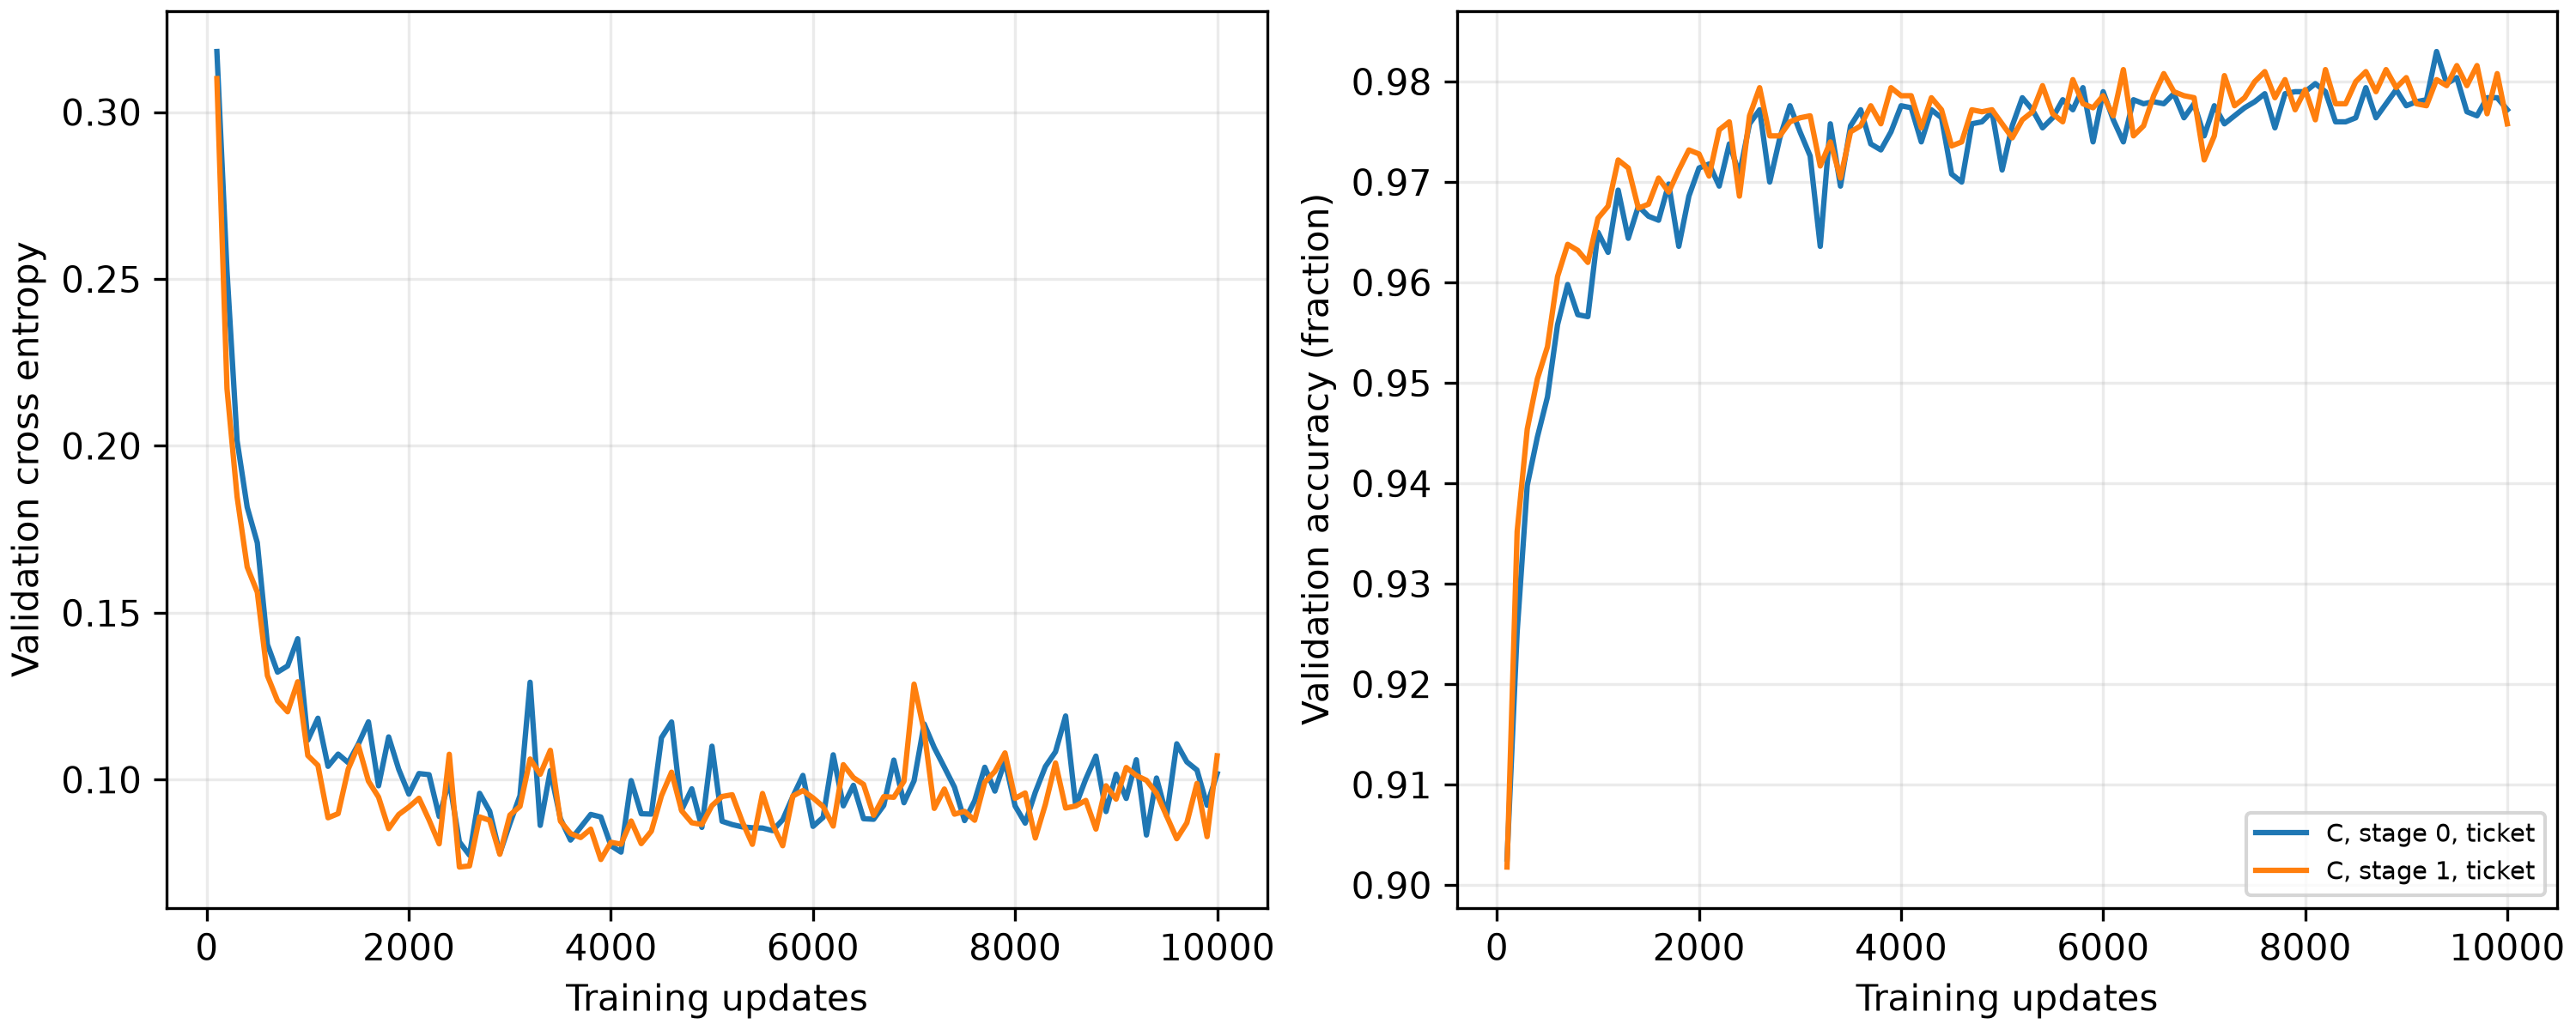

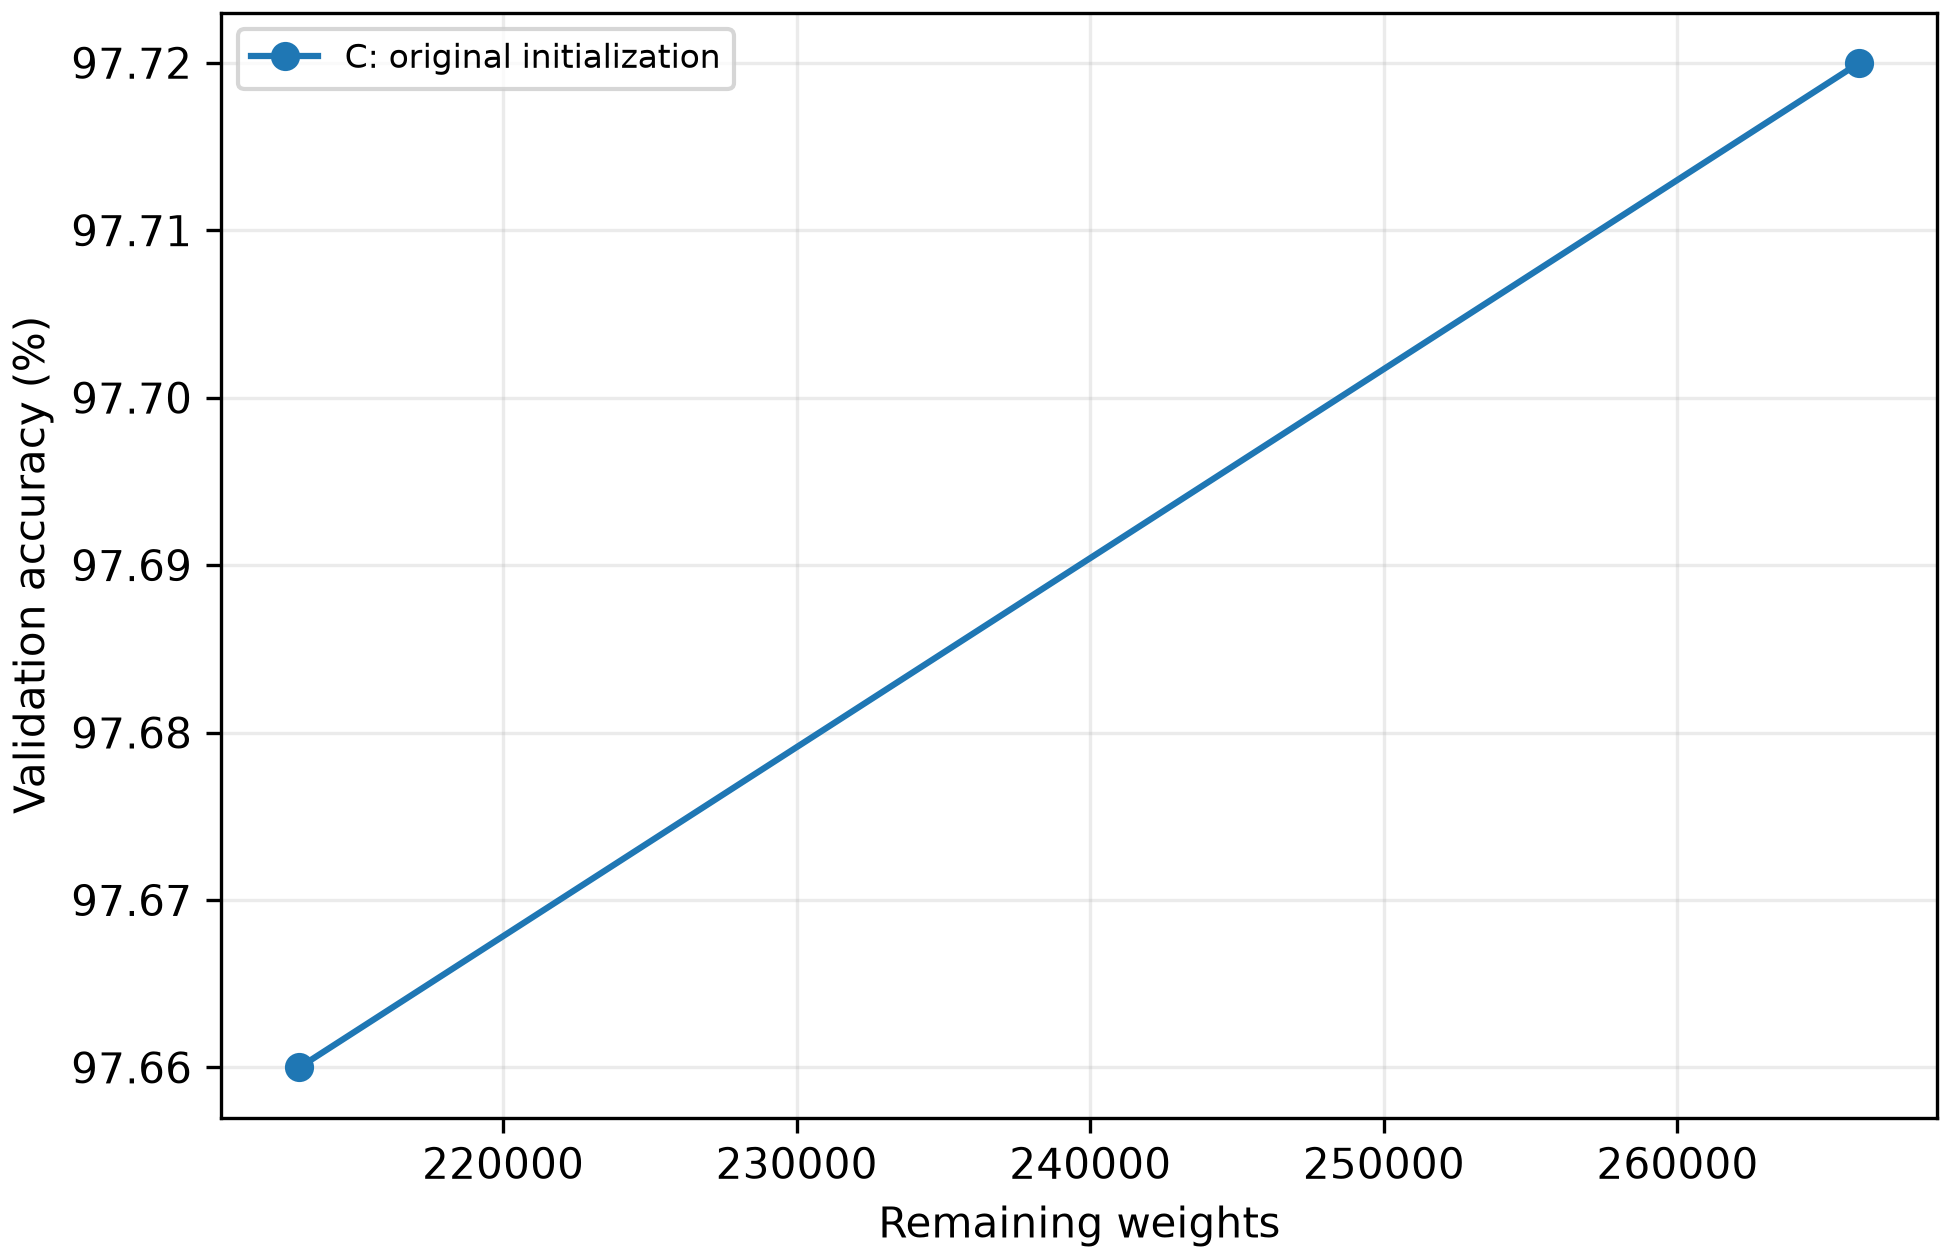

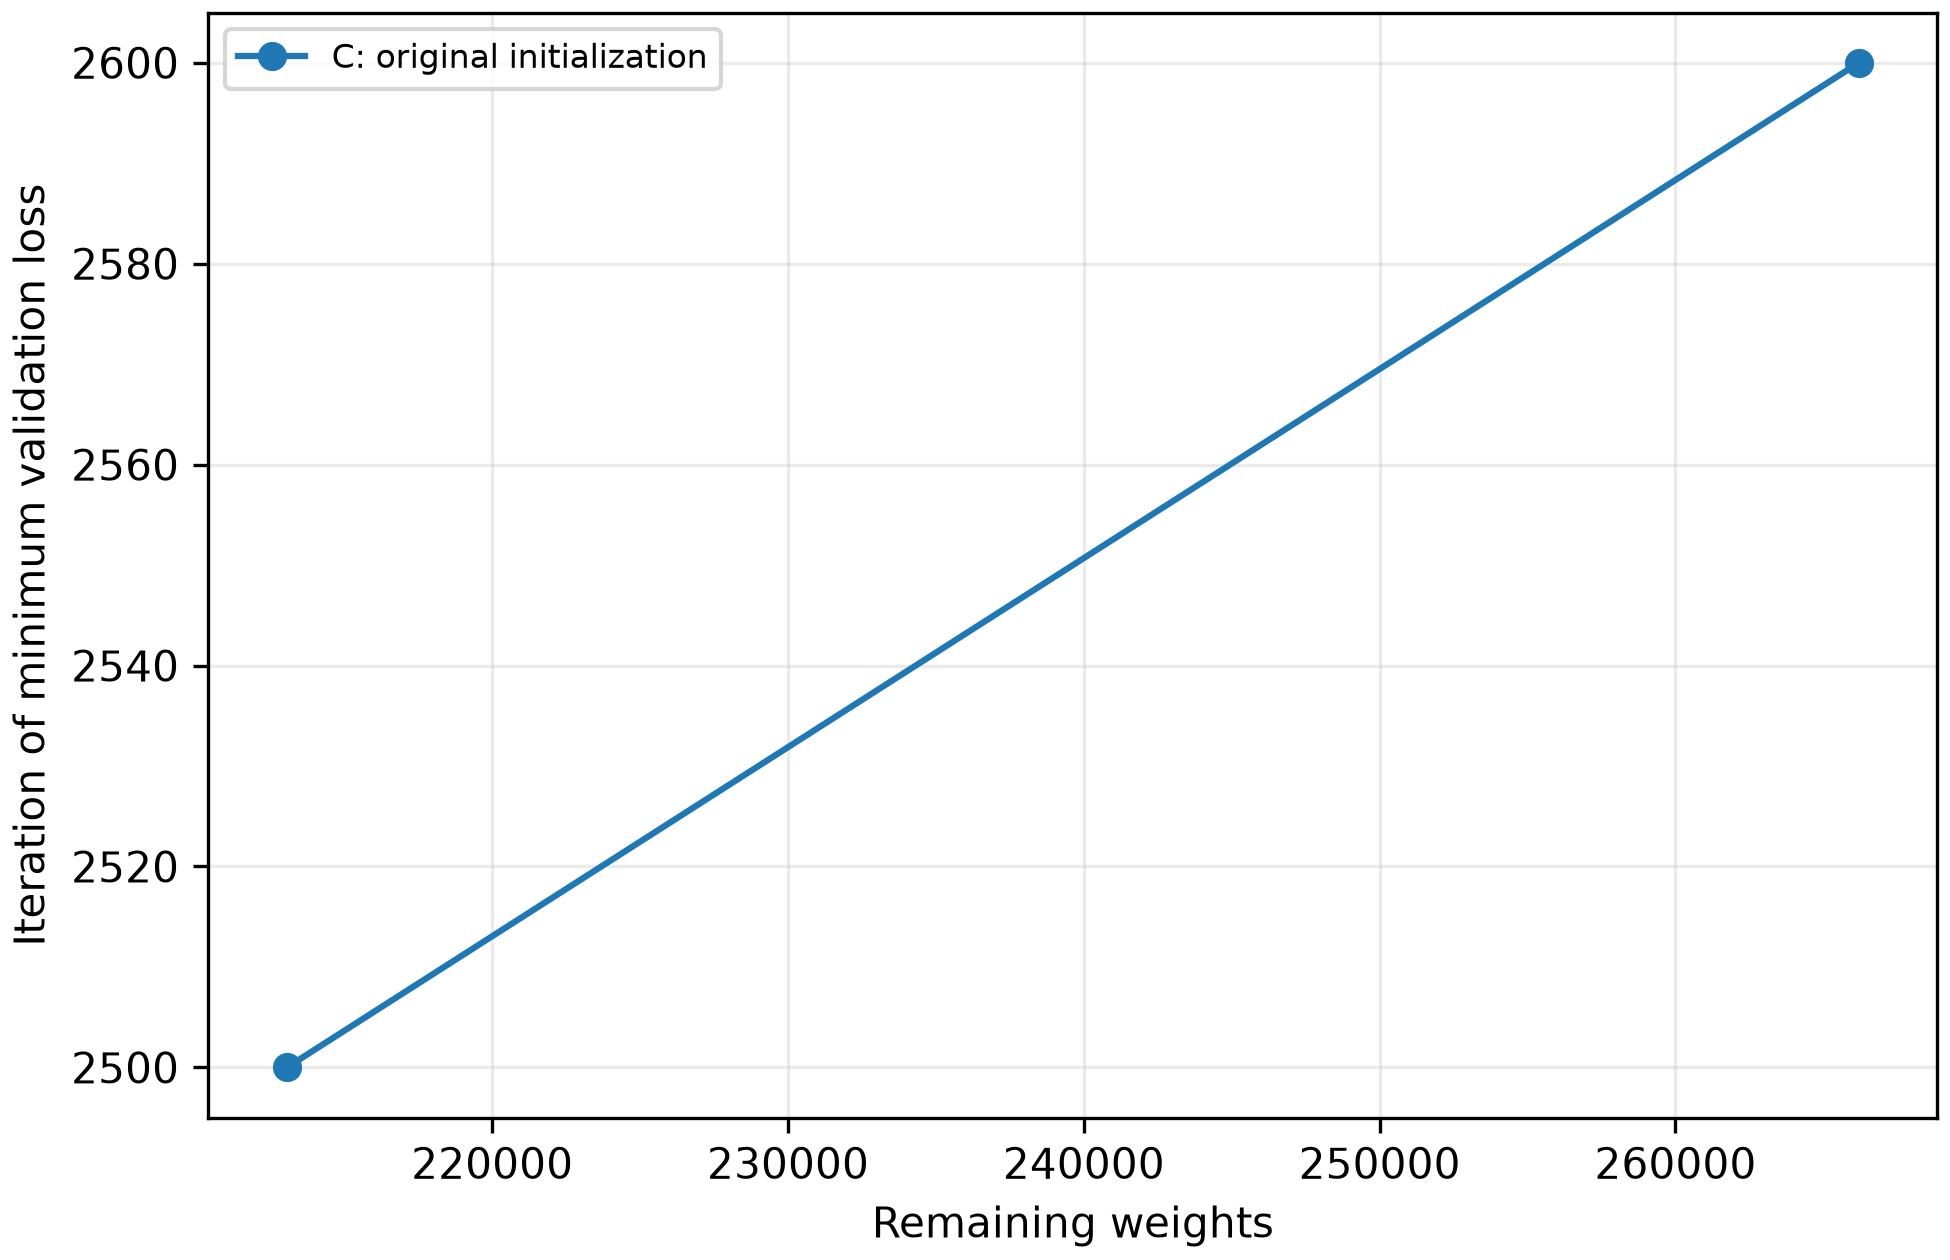

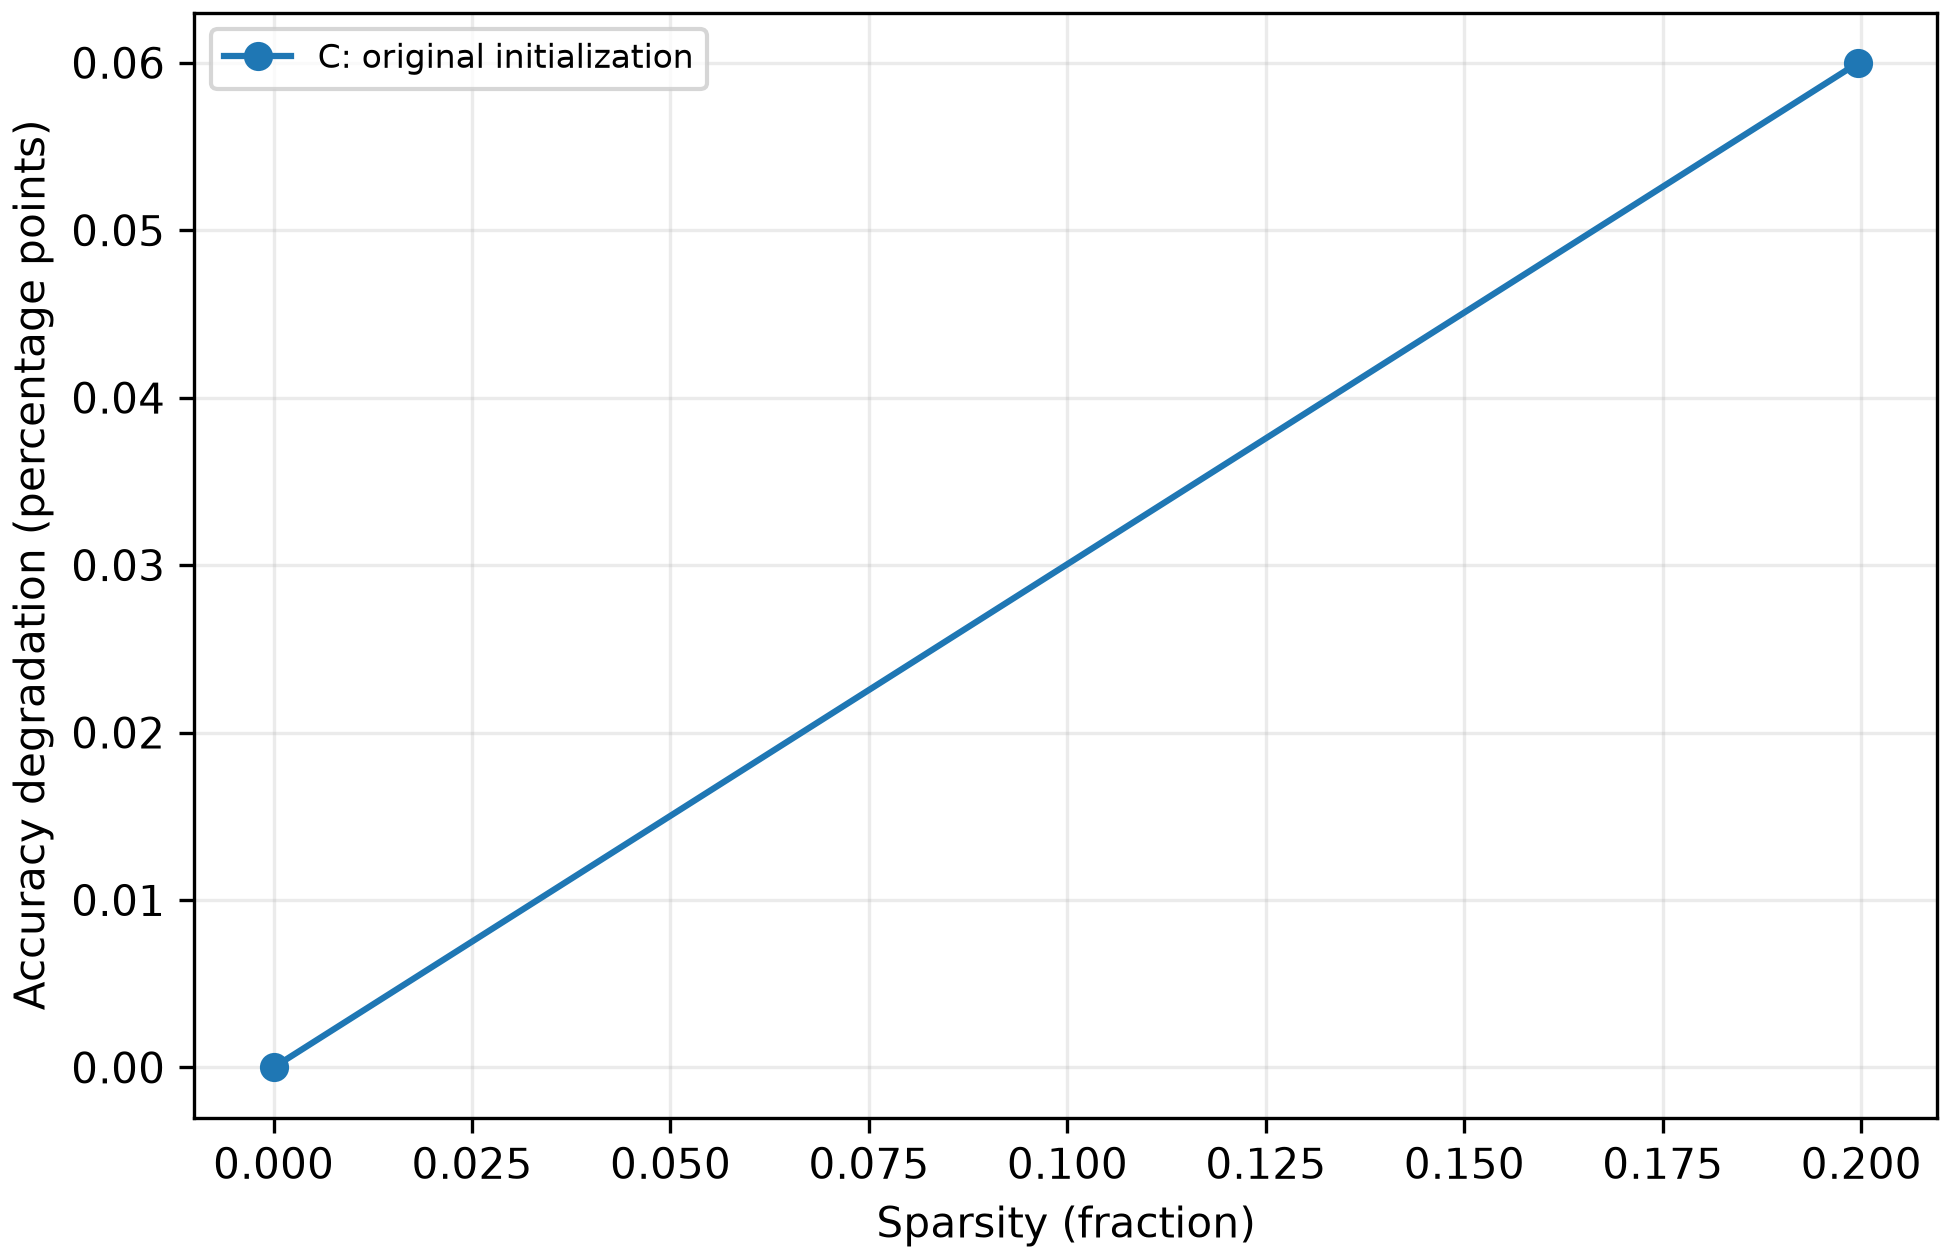

In [3]:
diagnostics = pilot_diagnostics(run_dir)
display(diagnostics)
for name in ("learning_curves", "accuracy", "trainability", "degradation"):
    display(Image(filename=str(run_dir / f"{name}.png")))

## Runtime probes and full-run estimates

The following two **dense-only, 500-update timing probes** account for A/B matrix shapes. These are not full experiments or convergence tests. Extrapolations include validation every 100 updates, assume serial CPU execution, and do not assume sparse speedups: masks leave PyTorch's dense matrix operations unchanged. Short-probe overhead and different hardware make these estimates approximate. The 25% allowance is a planning margin, not a statistical confidence interval. Controls roughly double cost.

In [4]:
benchmarks = []
for architecture in ("legacy_A", "legacy_B"):
    _, benchmark = run_experiment(architecture=architecture, seed=0, rounds=0,
        iterations=500, eval_interval=100, output_dir=run_dir / "timing_probes",
        data_dir=config["data_dir"], device=config["device"], download=False,
        save_plots=False, num_threads=4)
    benchmarks.append(benchmark)
legacy_names = {"legacy_A": "A", "legacy_B": "B", "LeNet300100": "C"}
legacy_results = results.assign(architecture=results.architecture.replace(legacy_names))
legacy_benchmarks = [frame.assign(architecture=frame.architecture.replace(legacy_names)) for frame in benchmarks]
costs, timings = estimate_cost(legacy_results, legacy_benchmarks)
timings.to_csv(run_dir / "runtime_measurements.csv", index=False)
costs.to_csv(run_dir / "cost_estimates.csv", index=False)
display(timings)
display(costs)

A, seed 0, stage 0: dense


Training:   0%|          | 0/500 [00:00<?, ?step/s]

B, seed 0, stage 0: dense


Training:   0%|          | 0/500 [00:00<?, ?step/s]

,architecture,stage,iterations,runtime_seconds,seconds_per_update
0,C,0,10000,120.597990,0.012060
1,C,1,10000,150.367228,0.015037
2,A,0,500,5.570456,0.011141
3,B,0,500,5.513430,0.011027


,stage_interpretation,iterations_per_stage,seeds_per_architecture,architectures,with_controls,training_stages,total_updates,estimated_hours,planning_hours_plus_25_percent
0,13 total stages (dense + 12 pruning rounds),10000,3,"A,B,C",False,117,1170000,3.869237,4.836546
1,13 total stages (dense + 12 pruning rounds),10000,3,"A,B,C",True,225,2250000,7.440840,9.301050
2,dense + 13 pruning rounds,10000,3,"A,B,C",False,126,1260000,4.166871,5.208588
3,dense + 13 pruning rounds,10000,3,"A,B,C",True,243,2430000,8.036108,10.045134
4,13 total stages (dense + 12 pruning rounds),50000,3,"A,B,C",False,117,5850000,19.346185,24.182731
5,13 total stages (dense + 12 pruning rounds),50000,3,"A,B,C",True,225,11250000,37.204202,46.505252
6,dense + 13 pruning rounds,50000,3,"A,B,C",False,126,6300000,20.834353,26.042941
7,dense + 13 pruning rounds,50000,3,"A,B,C",True,243,12150000,40.180538,50.225672


## Interpreting the verification

Compare update 200 with the minimum-validation-loss point and the final point. A minimum at the final update means the budget may still be limiting; a minimum earlier followed by rising loss suggests overfitting, not a reason to stop the IMP training early. This single-seed, lightly pruned pilot cannot establish convergence at other widths or high sparsity.

For a paper-faithful full study, the recommended budget remains **50,000 updates per stage**, fixed across A/B/C and seeds, with validation every 100. A reduced 10,000-update study must be labeled a deviation and validated across architectures and sparse stages first. Do not launch the full experiment until these diagnostics and costs have been reviewed.